# P2.12 · Small VAE on MNIST (reconstruction-loss choice, ELBO with reparameterization)

**ID:** P2.12 · **Target:** 35 min · **Plan week:** 4 · **Part:** P (PyTorch first principles)

**The drill.** Train a fully connected VAE (784 → 400 → z=20 → 400 → 784) on MNIST by maximizing the ELBO

$$\mathcal{L}(x) = \mathbb{E}_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)] - \mathrm{KL}\big(q_\phi(z\mid x)\,\|\,\mathcal{N}(0, I)\big),\qquad
q_\phi(z\mid x) = \mathcal{N}(\mu_\phi(x), \operatorname{diag}\sigma^2_\phi(x)),$$

with the reparameterization $z = \mu + \sigma \odot \varepsilon,\ \varepsilon \sim \mathcal{N}(0, I)$ and the closed-form KL
$\mathrm{KL} = -\tfrac12 \sum_j (1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2)$ (Kingma & Welling 2013, Appendix B).

**Must include (from the plan):** reconstruction-loss choice, ELBO with reparameterization. Concretely:
Bernoulli likelihood (BCE on [0, 1] pixels, from **logits**) vs Gaussian likelihood (MSE / 2σ²), and what the
choice does to the balance with the KL. Closed-form KL **checked against `torch.distributions.kl_divergence`**, the
reparameterization checked (gradients reach μ and log σ², sample moments right), initial-loss check
(784 · ln 2), overfit-one-batch, a grid of reconstructions and of samples from the prior.

**Rules.** No docs, no LLM. MNIST is in `DATA` (`download=False`). Each solution cell keeps only its spec.

## Sources
- D. P. Kingma, M. Welling, *Auto-Encoding Variational Bayes*, ICLR 2014, arXiv:1312.6114 —
  https://arxiv.org/abs/1312.6114 (ELBO, reparameterization trick, Gaussian KL in Appendix B).
- C. Doersch, *Tutorial on Variational Autoencoders*, 2016, arXiv:1606.05908 — https://arxiv.org/abs/1606.05908
  (intuition; Gaussian decoder σ as the reconstruction/KL trade-off).
- pytorch/examples `vae/main.py` (architecture 784-400-20, Adam 1e-3, batch 128, BCE + KL summed), commit acc295d,
  BSD-3: https://github.com/pytorch/examples/blob/acc295dc7b90714f1bf47f06004fc19a7fe235c4/vae/main.py.
  Adapted: the decoder returns logits and uses `binary_cross_entropy_with_logits` (stable), and the loss is
  averaged over the batch.
- G. Loaiza-Ganem, J. P. Cunningham, *The continuous Bernoulli: fixing a pervasive error in variational
  autoencoders*, NeurIPS 2019, arXiv:1907.06845 — https://arxiv.org/abs/1907.06845 (BCE on non-binary pixels is
  not a normalized likelihood).
- S. R. Bowman et al., *Generating Sentences from a Continuous Space*, CoNLL 2016, arXiv:1511.06349 —
  https://arxiv.org/abs/1511.06349 (posterior collapse; KL annealing).
- `torch.distributions.kl_divergence` / `Normal` docs: https://docs.pytorch.org/docs/stable/distributions.html

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.distributions import Normal, kl_divergence
from torch.utils.data import DataLoader, TensorDataset

from prep import DATA, Session, check, check_close, seed_everything

s = Session("P2.12", target_min=35)
seed_everything(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

[P2.12] started 16:45; target 35 min


In [2]:
# 1. DATA. torchvision.datasets.MNIST(DATA, train=True/False, download=False). `.data` uint8 -> float in [0, 1],
#    flattened (N, 784). Do NOT standardize (the Bernoulli decoder needs targets in [0, 1]).
#    Val = last 5000 of a seeded permutation of train (generator seed 0). DataLoaders: train batch 128 shuffle;
#    val/test batch 1000. (Labels are not used.)
tr = torchvision.datasets.MNIST(DATA, train=True, download=False)
te = torchvision.datasets.MNIST(DATA, train=False, download=False)
X_all = tr.data.float().div(255).reshape(-1, 784)
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(0))
X_train, X_val = X_all[perm[:55000]], X_all[perm[55000:]]
X_test = te.data.float().div(255).reshape(-1, 784)
print(X_train.shape, X_val.shape, X_test.shape, X_train.min().item(), X_train.max().item(),
      f"fraction of pixels strictly between 0 and 1: {((X_train > 0) & (X_train < 1)).float().mean():.3f}")
train_dl = DataLoader(TensorDataset(X_train), batch_size=128, shuffle=True)
val_dl = DataLoader(TensorDataset(X_val), batch_size=1000)
test_dl = DataLoader(TensorDataset(X_test), batch_size=1000)

torch.Size([55000, 784]) torch.Size([5000, 784]) torch.Size([10000, 784]) 0.0 1.0 fraction of pixels strictly between 0 and 1: 0.184


In [3]:
# 2. CLOSED-FORM KL. kl_std_normal(mu, logvar) -> (B,): KL( N(mu, exp(logvar)) || N(0, I) ) summed over latent dims:
#    -0.5 * sum(1 + logvar - mu^2 - exp(logvar), dim=-1).
def kl_std_normal(mu, logvar):
    return -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=-1)

In [4]:
# 3. MODEL. `VAE(d_in=784, d_h=400, d_z=20)`:
#    encode(x) -> (mu, logvar): Linear(784,400) + ReLU, then two heads Linear(400,20) for mu and for logvar.
#    reparameterize(mu, logvar) -> z = mu + exp(0.5*logvar) * eps, eps = randn_like.
#    decode(z) -> LOGITS (B, 784): Linear(20,400) + ReLU + Linear(400,784). (No sigmoid: the loss takes logits.)
#    forward(x) -> (logits, mu, logvar). make_model() -> fresh VAE on `dev`.
class VAE(nn.Module):
    def __init__(self, d_in=784, d_h=400, d_z=20):
        super().__init__()
        self.d_z = d_z
        self.enc = nn.Sequential(nn.Linear(d_in, d_h), nn.ReLU())
        self.mu, self.logvar = nn.Linear(d_h, d_z), nn.Linear(d_h, d_z)
        self.dec = nn.Sequential(nn.Linear(d_z, d_h), nn.ReLU(), nn.Linear(d_h, d_in))

    def encode(self, x):
        h = self.enc(x)
        return self.mu(h), self.logvar(h)

    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decode(self.reparameterize(mu, logvar)), mu, logvar


def make_model():
    return VAE().to(dev)

In [5]:
# 4. NEGATIVE ELBO. neg_elbo(logits, x, mu, logvar, recon="bce", sigma=1.0) -> (loss, recon_term, kl_term), all
#    per-example quantities SUMMED over pixels / latent dims and AVERAGED over the batch (python-level scalars are fine
#    as tensors). recon="bce": F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(-1)
#    (= -log Bernoulli(x | sigmoid(logits))). recon="gauss": ((sigmoid(logits) - x)^2).sum(-1) / (2 sigma^2)
#    (Gaussian NLL up to the constant 784 * log(sigma * sqrt(2 pi))).
def neg_elbo(logits, x, mu, logvar, recon="bce", sigma=1.0):
    if recon == "bce":
        rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(-1)
    elif recon == "gauss":
        rec = (torch.sigmoid(logits) - x).pow(2).sum(-1) / (2 * sigma**2)
    else:
        raise ValueError(recon)
    kl = kl_std_normal(mu, logvar)
    return (rec + kl).mean(), rec.mean(), kl.mean()

In [6]:
# 5. SANITY CHECKS.
#    (a) `init_recon`: BCE recon term of a fresh model on one val batch (expect ≈ 784 ln 2 ≈ 543: logits ≈ 0 -> p = 0.5
#        for every pixel, whatever x is).
#    (b) Reparameterization: for fixed mu = [1, -2], logvar = log([0.25, 4]) draw 100 000 samples ->
#        `z_mean`, `z_std` (expect mu and [0.5, 2]); and one backward of z.sum() must give non-None grads on
#        mu and logvar (`grads_ok`).
#    (c) Overfit one batch of 64 with a fresh model, Adam lr=1e-3, 1000 steps, BCE ELBO ->
#        `overfit_recon` (recon term at the end; expect far below init, e.g. < 0.3 * init_recon).
torch.manual_seed(0)
m0 = make_model()
xb = X_val[:256].to(dev)
with torch.no_grad():
    logits, mu, logvar = m0(xb)
    _, init_recon, init_kl = neg_elbo(logits, xb, mu, logvar)
init_recon = init_recon.item()
print(f"init recon {init_recon:.1f} vs 784 ln2 = {784 * math.log(2):.1f}; init KL {init_kl.item():.2f}")

mu_t = torch.tensor([1.0, -2.0], requires_grad=True)
lv_t = torch.log(torch.tensor([0.25, 4.0])).requires_grad_()
z = m0.reparameterize(mu_t.expand(100_000, 2), lv_t.expand(100_000, 2))
z_mean, z_std = z.mean(0).detach(), z.std(0).detach()
z.sum().backward()
grads_ok = mu_t.grad is not None and lv_t.grad is not None
print("z mean", z_mean.tolist(), "z std", z_std.tolist(), "grads reach mu/logvar:", grads_ok)

tmp = make_model()
tmp_opt = torch.optim.Adam(tmp.parameters(), lr=1e-3)
xb = X_train[:64].to(dev)
for _ in range(1000):
    logits, mu, logvar = tmp(xb)
    loss, rec, kl = neg_elbo(logits, xb, mu, logvar)
    tmp_opt.zero_grad()
    loss.backward()
    tmp_opt.step()
overfit_recon = rec.item()
print(f"overfit-one-batch: recon {overfit_recon:.1f}, KL {kl.item():.1f}")

init recon 550.2 vs 784 ln2 = 543.4; init KL 0.09
z mean [1.0025029182434082, -1.9982476234436035] z std [0.5002065896987915, 1.9969114065170288] grads reach mu/logvar: True


overfit-one-batch: recon 54.4, KL 19.3


In [7]:
# 6. TRAIN (Bernoulli decoder). `fit(recon, epochs, sigma=1.0) -> (model, history)`: torch.manual_seed(0), fresh model,
#    Adam lr=1e-3, per epoch log train neg-ELBO and val (neg-ELBO, recon, KL) via
#    `evaluate(model, dl, recon, sigma) -> dict(loss, recon, kl)` (eval mode, no_grad, weighted by batch size over the
#    whole set; z is still sampled, a 1-sample ELBO estimate). history keys: "train", "val".
#    vae_bce, hist_bce = fit("bce", epochs=10).
@torch.no_grad()
def evaluate(model, dl, recon="bce", sigma=1.0):
    model.eval()
    tot = {"loss": 0.0, "recon": 0.0, "kl": 0.0}
    n = 0
    for (xb,) in dl:
        xb = xb.to(dev)
        logits, mu, logvar = model(xb)
        vals = neg_elbo(logits, xb, mu, logvar, recon=recon, sigma=sigma)
        for k, v in zip(tot, vals):
            tot[k] += v.item() * len(xb)
        n += len(xb)
    return {k: v / n for k, v in tot.items()}


def fit(recon, epochs, sigma=1.0):
    torch.manual_seed(0)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = {"train": [], "val": []}
    for epoch in range(epochs):
        model.train()
        tot, n = 0.0, 0
        for (xb,) in train_dl:
            xb = xb.to(dev)
            logits, mu, logvar = model(xb)
            loss, _, _ = neg_elbo(logits, xb, mu, logvar, recon=recon, sigma=sigma)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb)
            n += len(xb)
        history["train"].append(tot / n)
        history["val"].append(evaluate(model, val_dl, recon, sigma))
        v = history["val"][-1]
        print(f"  [{recon}] epoch {epoch + 1:2d} train {tot / n:7.2f}  val {v['loss']:7.2f} (recon {v['recon']:7.2f}, KL {v['kl']:5.2f})")
    return model, history


vae_bce, hist_bce = fit("bce", epochs=10)

  [bce] epoch  1 train  168.03  val  132.00 (recon  112.29, KL 19.71)


  [bce] epoch  2 train  124.29  val  119.10 (recon   96.66, KL 22.44)


  [bce] epoch  3 train  116.16  val  114.41 (recon   90.23, KL 24.18)


  [bce] epoch  4 train  112.73  val  112.04 (recon   87.39, KL 24.65)


  [bce] epoch  5 train  110.68  val  110.60 (recon   85.73, KL 24.87)


  [bce] epoch  6 train  109.39  val  109.36 (recon   84.70, KL 24.66)


  [bce] epoch  7 train  108.45  val  108.88 (recon   83.84, KL 25.03)


  [bce] epoch  8 train  107.75  val  108.18 (recon   83.06, KL 25.12)


  [bce] epoch  9 train  107.16  val  107.73 (recon   82.70, KL 25.03)


  [bce] epoch 10 train  106.72  val  107.26 (recon   81.71, KL 25.55)


In [8]:
# 7. RECONSTRUCTION-LOSS CHOICE. Train the same VAE with the Gaussian decoder, sigma = 1 ("plain MSE / 2"), 5 epochs:
#    vae_gauss, hist_gauss = fit("gauss", 5, sigma=1.0). Compare the val KL of both models (`kl_bce`, `kl_gauss`)
#    and say what happened (look at the scale of the recon term vs the KL term).
vae_gauss, hist_gauss = fit("gauss", epochs=5, sigma=1.0)
kl_bce, kl_gauss = hist_bce["val"][-1]["kl"], hist_gauss["val"][-1]["kl"]
print(f"val KL: Bernoulli decoder {kl_bce:.2f} nats vs Gaussian sigma=1 decoder {kl_gauss:.2f} nats")

  [gauss] epoch  1 train   25.58  val   22.43 (recon   18.17, KL  4.26)


  [gauss] epoch  2 train   21.78  val   21.19 (recon   16.06, KL  5.13)


  [gauss] epoch  3 train   20.91  val   20.63 (recon   14.98, KL  5.65)


  [gauss] epoch  4 train   20.49  val   20.35 (recon   14.24, KL  6.11)


  [gauss] epoch  5 train   20.22  val   20.19 (recon   14.13, KL  6.05)
val KL: Bernoulli decoder 25.55 nats vs Gaussian sigma=1 decoder 6.05 nats


test neg-ELBO 106.03 nats (recon 80.40, KL 25.63)


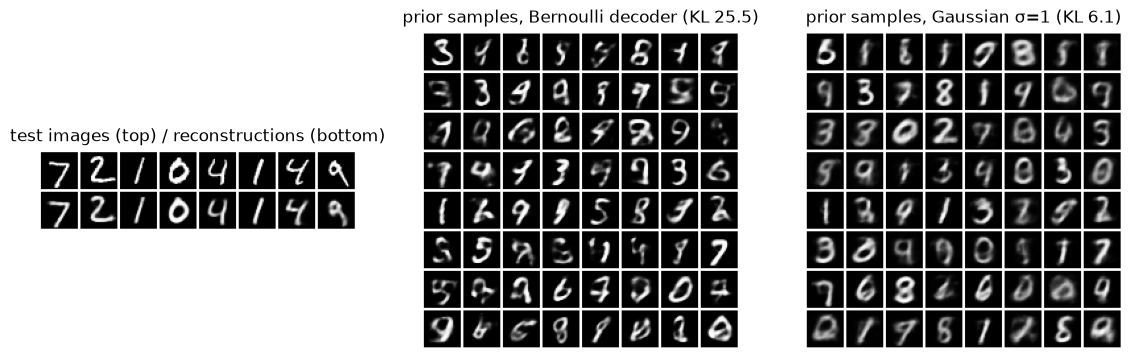

In [9]:
# 8. TEST + GRIDS (test once). `test_metrics = evaluate(vae_bce, test_dl)`; print neg-ELBO in nats/example.
#    Figure: row 1 = 8 test images, row 2 = their reconstructions sigmoid(logits) by vae_bce; then 8x8 grids of
#    samples decode(z), z ~ N(0, I), for vae_bce and vae_gauss side by side (torchvision.utils.make_grid).
test_metrics = evaluate(vae_bce, test_dl)
print(f"test neg-ELBO {test_metrics['loss']:.2f} nats (recon {test_metrics['recon']:.2f}, KL {test_metrics['kl']:.2f})")
vae_bce.eval(); vae_gauss.eval()
with torch.no_grad():
    x8 = X_test[:8].to(dev)
    rec8 = torch.sigmoid(vae_bce.decode(vae_bce.encode(x8)[0]))  # decode the posterior mean
    z = torch.randn(64, vae_bce.d_z, device=dev)
    samp_bce = torch.sigmoid(vae_bce.decode(z))
    samp_gauss = torch.sigmoid(vae_gauss.decode(z))
grid = lambda t, nrow: torchvision.utils.make_grid(t.reshape(-1, 1, 28, 28).cpu(), nrow=nrow, pad_value=1).permute(1, 2, 0)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 2, 2]})
ax[0].imshow(grid(torch.cat([x8, rec8]), 8)); ax[0].set_title("test images (top) / reconstructions (bottom)")
ax[1].imshow(grid(samp_bce, 8)); ax[1].set_title(f"prior samples, Bernoulli decoder (KL {kl_bce:.1f})")
ax[2].imshow(grid(samp_gauss, 8)); ax[2].set_title(f"prior samples, Gaussian σ=1 (KL {kl_gauss:.1f})")
for a in ax:
    a.axis("off")
plt.show()

## Self-check
Expects: `X_train`, `kl_std_normal`, `VAE`/`make_model` (encode/reparameterize/decode/forward), `neg_elbo`,
`init_recon`, `z_mean`, `z_std`, `grads_ok`, `overfit_recon`, `vae_bce`, `kl_bce`, `kl_gauss`, `test_metrics`.

In [10]:
torch.manual_seed(1)
mu_r, lv_r = torch.randn(16, 20) * 2, torch.randn(16, 20)
ref = kl_divergence(Normal(mu_r, torch.exp(0.5 * lv_r)), Normal(torch.zeros(20), torch.ones(20))).sum(-1)
check_close("closed-form KL == torch.distributions", kl_std_normal(mu_r, lv_r), ref, atol=1e-4)
check_close("KL(N(0,1) || N(0,1)) == 0", kl_std_normal(torch.zeros(3, 20), torch.zeros(3, 20)), torch.zeros(3))
check("pixels in [0, 1], not standardized", X_train.min().item() >= 0 and X_train.max().item() <= 1)
x_r, l_r = torch.rand(8, 784), torch.randn(8, 784)
_, rec_r, kl_r = neg_elbo(l_r, x_r, mu_r[:8], lv_r[:8])
check_close("BCE recon = per-example SUM over pixels, batch MEAN",
            rec_r, F.binary_cross_entropy(torch.sigmoid(l_r), x_r, reduction="sum") / 8, rtol=1e-4)
check_close("KL term = batch mean of per-example KL", kl_r, ref[:8].mean(), atol=1e-4)
_, rec_g, _ = neg_elbo(l_r, x_r, mu_r[:8], lv_r[:8], recon="gauss", sigma=0.5)
check_close("Gaussian recon = SSE / (2 sigma^2), batch mean", rec_g, ((torch.sigmoid(l_r) - x_r) ** 2).sum() / 8 / (2 * 0.25), rtol=1e-4)
check("decoder returns logits (no Sigmoid module)", not any(isinstance(m, nn.Sigmoid) for m in vae_bce.modules()))
check("initial recon ~ 784 ln 2", abs(init_recon - 784 * math.log(2)) < 0.1 * 784 * math.log(2), f"got {init_recon:.1f}")
check_close("reparameterized z mean", z_mean, [1.0, -2.0], atol=0.03)
check_close("reparameterized z std = exp(0.5 logvar)", z_std, [0.5, 2.0], atol=0.03)
check("gradients flow to mu and logvar", grads_ok)
check("can overfit one batch (recon << init)", overfit_recon < 0.3 * init_recon, f"got {overfit_recon:.1f}")
torch.manual_seed(0)
xb = X_val[:500].to(dev)
vae_bce.eval()
with torch.no_grad():
    lg, mu_b, lv_b = vae_bce(xb)
check("forward shapes", lg.shape == (500, 784) and mu_b.shape == lv_b.shape and mu_b.shape[0] == 500)
check("test neg-ELBO < 125 nats", test_metrics["loss"] < 125, f"got {test_metrics['loss']:.1f}")
check("Bernoulli VAE uses its latent (KL > 10 nats)", kl_bce > 10, f"got {kl_bce:.1f}")
check("Gaussian sigma=1 decoder nearly collapses the posterior (KL much smaller)", kl_gauss < 0.5 * kl_bce, f"{kl_gauss:.1f} vs {kl_bce:.1f}")

ok  closed-form KL == torch.distributions
ok  KL(N(0,1) || N(0,1)) == 0
ok  pixels in [0, 1], not standardized
ok  BCE recon = per-example SUM over pixels, batch MEAN
ok  KL term = batch mean of per-example KL
ok  Gaussian recon = SSE / (2 sigma^2), batch mean
ok  decoder returns logits (no Sigmoid module)
ok  initial recon ~ 784 ln 2
ok  reparameterized z mean
ok  reparameterized z std = exp(0.5 logvar)
ok  gradients flow to mu and logvar
ok  can overfit one batch (recon << init)
ok  forward shapes
ok  test neg-ELBO < 125 nats
ok  Bernoulli VAE uses its latent (KL > 10 nats)
ok  Gaussian sigma=1 decoder nearly collapses the posterior (KL much smaller)


## Say it out loud (P3)
1. Derive the ELBO from log p(x) in two lines. Which term is the "reconstruction" and which the "regularizer"?
2. Why the reparameterization trick? What would the gradient estimator be without it, and why is it worse?
3. Derive the closed-form KL between N(μ, σ²) and N(0, 1) for one dimension.
4. BCE vs MSE for the reconstruction: which likelihood does each correspond to? MNIST pixels aren't binary: is BCE still a valid likelihood?
5. Why did the σ = 1 Gaussian decoder end up with a tiny KL and blurry, similar-looking samples? What σ would you use, and how would you set it?
6. Why should the decoder output logits, and why sum over pixels (not mean) inside the ELBO?
7. What is posterior collapse, and name two fixes.
8. Why log σ² as the encoder output instead of σ?

<details><summary>Model answers</summary>

1. log p(x) = log ∫ p(x|z)p(z) dz = log E_q[p(x|z)p(z)/q(z|x)] ≥ E_q[log p(x|z)] − KL(q(z|x) ‖ p(z)) by Jensen.
   The gap is KL(q(z|x) ‖ p(z|x)). The first term is reconstruction (expected log-likelihood); the KL is the
   regularizer that keeps q close to the prior, so that sampling z ~ N(0, I) produces data.
2. We need ∇_φ E_{q_φ}[f(z)]. Writing z = μ + σ ⊙ ε with ε ~ N(0, I) moves φ inside the expectation, so we can
   backprop through f (the pathwise estimator). Without it we would need the score-function / REINFORCE estimator
   E[f(z) ∇ log q_φ(z)], which is unbiased but has much higher variance (Kingma & Welling 2013, §2.2-2.4).
3. KL = E_q[log q − log p] = E[−½log 2πσ² − (z−μ)²/2σ² + ½log 2π + z²/2] = −½log σ² − ½ + ½(σ² + μ²).
   Summing over d dims gives −½ Σ(1 + log σ² − μ² − σ²).
4. BCE is −log Bernoulli(x | p). MSE/(2σ²) is the Gaussian NLL with fixed variance, up to a constant. Grey MNIST
   pixels in (0, 1) make BCE an unnormalized "likelihood". Loaiza-Ganem & Cunningham (2019) fix this with the
   continuous Bernoulli. In practice people either binarize the pixels (a true Bernoulli) or accept BCE as a
   loss: it works well, but its value is not an exact NLL in nats.
5. With σ = 1, the reconstruction term is SSE/2. Always predicting the mean training image already scores about
   26 nats, and the trained model reaches only about 14. Encoding z can therefore buy at most a dozen nats, while
   every nat of KL costs a full nat. The optimum encodes very little (KL ≈ 6 nats here, against ≈ 25 with the
   Bernoulli decoder), so the samples are blurry and look alike. A
   Gaussian decoder needs a realistic σ (pixel noise is about 0.1, i.e. weights about 50× larger), or a learned σ
   (per pixel or global, optimized with its log-normalizer), or equivalently a β < 1 weight on the KL (Doersch's
   tutorial discusses σ as this trade-off).
6. Logits + `binary_cross_entropy_with_logits` use the stable log-sum-exp form. sigmoid then BCE saturates at 0/1
   and PyTorch has to clamp log(0) to −100. The ELBO is a log-likelihood of the whole image: log p(x|z) = Σ over
   pixels. Averaging over the 784 pixels silently divides the reconstruction by 784 relative to the KL (a huge β),
   which causes posterior collapse.
7. The decoder ignores z and q(z|x) ≈ p(z) (KL ≈ 0), common with strong decoders (autoregressive) or an
   over-weighted KL. Fixes: KL annealing / warm-up (Bowman et al. 2016), free bits (a minimum KL per dimension),
   a weaker decoder, β < 1.
8. σ must be positive. log σ² is unconstrained, so a plain Linear head can output it. exp(0.5·logvar) gives σ
   and logvar.exp() gives σ², both cheap and stable. Softplus-parameterized σ is a common alternative.
</details>

In [11]:
s.finish(lookups=0, score=None, notes="")  # score: 1-5 self-rating; notes: what tripped you up

[P2.12] done in 0.5 min (within target 35 min)


0.5156432588895162